# Programming Assignment 3: Association Analysis, Deep Learning, and LLM-Based Text Classification

**Image dataset:** Animal_Classification (https://www.kaggle.com/datasets/ayushv322/animal-classification)  
**Classes:** Buffalo, Elephant, Rhino, Zebra  
**Text dataset:** student_8 tweet dataset  
**Transaction dataset:** Grocery_Items_8.csv  
**GitHub Link:** https://github.com/mfshahriar/Data-Mining  
**Banner ID Last Digit**: 8.


## 1. Association Rule Mining


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

DATA = Path.cwd() / "Grocery_Items_8.csv"

### 1(a) Dataset exploration


In [2]:
grocery = pd.read_csv(DATA)
print("Shape:", grocery.shape)

transactions = []
for row in grocery.values: 
    items = []
    for x in row:
        if pd.notna(x) and str(x).strip() != "":
            items.append(str(x).strip())
    transactions.append(items)

print("Number of transactions:", len(transactions))
#print(transactions[0])

Shape: (8000, 11)
Number of transactions: 8000


In [3]:
item_counts = {}
for items in transactions:
    for item in set(items):
        if item not in item_counts:
            item_counts[item] = 0
        item_counts[item] += 1

print("Number of unique items:", len(item_counts))

pairs = []
for item, count in item_counts.items():
    pairs.append((count, item))  

top3 = sorted(pairs, reverse=True)[:3]
print("Three most frequent items:")
for count, item in top3:
    print(item, ":", count)

Number of unique items: 166
Three most frequent items:
whole milk : 1266
other vegetables : 978
rolls/buns : 869


### 1(b) Association rule generation


In [4]:
encoder = TransactionEncoder()
item_table = pd.DataFrame( # availability true false table for each item in a transaction
    encoder.fit(transactions).transform(transactions),
    columns=encoder.columns_,
)
#print("Shape:", item_table.shape)

In [5]:
frequent = apriori(item_table, min_support=0.005, use_colnames=True)
rules = association_rules(frequent, metric="confidence", min_threshold=0.10)
print("Total number of rules:", len(rules))
top5 = rules.sort_values("lift", ascending=False).head(5)
top5[["antecedents", "consequents", "support", "confidence", "lift"]]


Total number of rules: 24


,antecedents,consequents,support,confidence,lift
18,(sausage),(soda),0.006250,0.104384,1.078906
0,(bottled beer),(whole milk),0.007375,0.158602,1.002225
2,(canned beer),(rolls/buns),0.005000,0.105541,0.971608
15,(pip fruit),(whole milk),0.007750,0.153465,0.969765
19,(sausage),(whole milk),0.009125,0.152401,0.963038


### 1(c) Parameter sensitivity analysis


In [6]:
min_supports = [0.002, 0.005, 0.01]
min_confidences = [0.05, 0.10, 0.15]
counts = pd.DataFrame(index=min_confidences, columns=min_supports)

for s in min_supports:
    freq = apriori(item_table, min_support=s, use_colnames=True)
    if len(freq) == 0:
        counts[s] = 0
        continue

    rules_all = association_rules(freq, metric="confidence", min_threshold=min(min_confidences))
    for c in min_confidences:
        counts.loc[c, s] = int((rules_all["confidence"] >= c).sum())

counts

,0.002,0.005,0.010
0.05,233,59,12
0.10,75,24,5
0.15,9,4,0


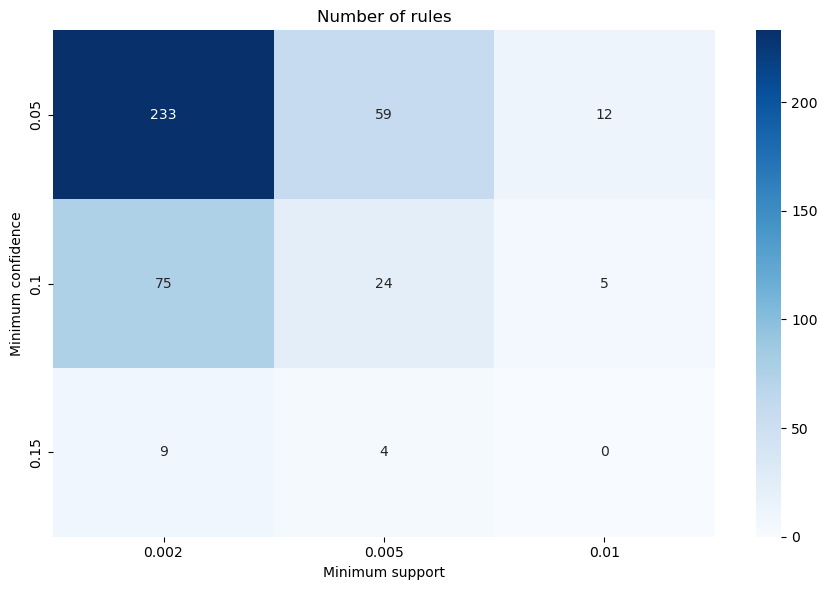

In [7]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

plt.figure(figsize=(9, 6))
sns.heatmap(counts.astype(int), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Minimum support")
plt.ylabel("Minimum confidence")
plt.title("Number of rules")
plt.tight_layout()
plt.show()


### 1(d) Interpretation


Increasing minimum support or confidence should decreases the number of rules, as you now have to pass a higher number to be considered as a rule. Intuitively, higher support means itemsets needs to be more frequent, and higher confidence means you need more X -> Y association to be considered for a rule.  

A rule can have high confidence but low lift. High confidence means for X -> Y, when X appears, Y is more likely to appear. Low lift means Y is already very frequent. Hence, maybe Y appears because its frequent, not necessarily because X appeared.  

## 2. Image Classification Using CNN

Dataset: **Animal_Classification** (Buffalo, Elephant, Rhino, Zebra)  
Framework: **PyTorch** (Working on TensorFlow with CUDA has become a hastle in Windows)


In [8]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

DATA_DIR = Path.cwd() / "Animal_Classification"
IMG_SIZE = 128 #resizing images to 128
BATCH_SIZE = 64
EPOCHS = 30
SEED = 48

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

full_data = datasets.ImageFolder(DATA_DIR, transform=transform)
class_names = full_data.classes
print("Classes:", class_names)
print("Total images:", len(full_data))

n_val = int(0.2 * len(full_data))
n_train = len(full_data) - n_val
train_set, val_set = random_split(
    full_data,
    [n_train, n_val],
    generator=torch.Generator().manual_seed(SEED),
) 

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)

print("Train size:", n_train)
print("Val size:", n_val)


Device: cuda
GPU: NVIDIA GeForce RTX 4080
Classes: ['Buffalo', 'Elephant', 'Rhino', 'Zebra']
Total images: 4000
Train size: 3200
Val size: 800


In [9]:
def make_cnn(n_classes, conv2_filters=8, conv2_kernel=3, hidden_neurons=16):
    after_pool1 = (IMG_SIZE - 3 + 1) // 2
    after_conv2 = after_pool1 - conv2_kernel + 1
    after_pool2 = after_conv2 // 2
    flat = conv2_filters * after_pool2 * after_pool2

    model = nn.Sequential(
        nn.Conv2d(3, 8, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(8, conv2_filters, kernel_size=conv2_kernel),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(flat, hidden_neurons),
        nn.ReLU(),
        nn.Linear(hidden_neurons, n_classes),
    )
    return model


def count_trainable(model):
    total = 0
    for p in model.parameters():
        if p.requires_grad:
            total += p.numel()
    return total


In [10]:
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)

    total_loss = 0.0
    correct = 0
    total = 0
    loss_fn = nn.CrossEntropyLoss()  # categorical cross-entropy, already places softmax

    with torch.set_grad_enabled(training):
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = loss_fn(logits, labels)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * labels.size(0)
            pred = logits.argmax(dim=1)
            correct += (pred == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total


In [11]:
def train_model(model, epochs=EPOCHS):
    model = model.to(device)
    optimizer = optim.Adam(model.parameters())

    history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}
    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch(model, train_loader, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch:02d}/{epochs}  "
            f"train_acc={train_acc:.4f}  val_acc={val_acc:.4f}"
        )
    return history


### 2(a) Baseline CNN


In [12]:
baseline = make_cnn(n_classes=len(class_names))
print(baseline)

n_params = count_trainable(baseline)
print("Trainable parameters:", n_params)

history_baseline = train_model(baseline, epochs=EPOCHS)


Sequential(
  (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 8, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=7200, out_features=16, bias=True)
  (8): ReLU()
  (9): Linear(in_features=16, out_features=4, bias=True)
)
Trainable parameters: 116092
Epoch 01/30  train_acc=0.4144  val_acc=0.5150
Epoch 02/30  train_acc=0.5681  val_acc=0.5938
Epoch 03/30  train_acc=0.6416  val_acc=0.6275
Epoch 04/30  train_acc=0.6663  val_acc=0.6325
Epoch 05/30  train_acc=0.6931  val_acc=0.6275
Epoch 06/30  train_acc=0.7219  val_acc=0.6750
Epoch 07/30  train_acc=0.7369  val_acc=0.6875
Epoch 08/30  train_acc=0.7412  val_acc=0.6787
Epoch 09/30  train_acc=0.7606  val_acc=0.6750
Epoch 10/30  train_acc=0.7806  val_acc=0.7175
Epoch 11/30  train_acc=0

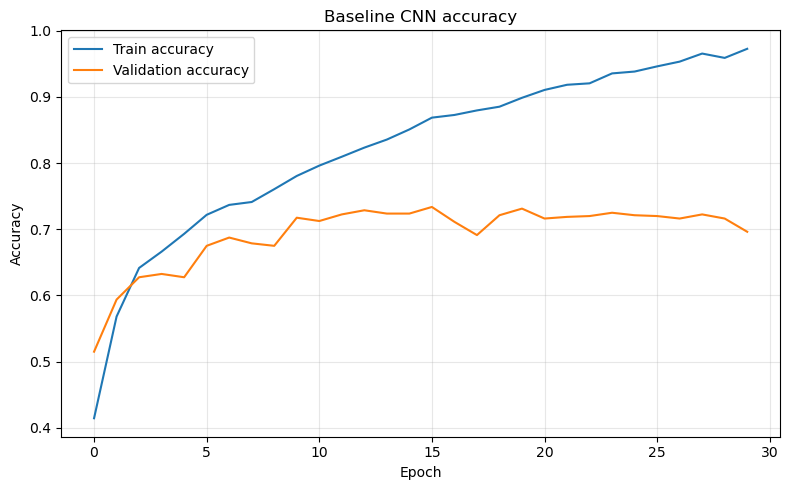

Final train accuracy: 0.9728
Final val accuracy:   0.6963


In [13]:
plt.figure(figsize=(8, 5))
plt.plot(history_baseline["train_acc"], label="Train accuracy")
plt.plot(history_baseline["val_acc"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline CNN accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Final train accuracy:", round(history_baseline["train_acc"][-1], 4))
print("Final val accuracy:  ", round(history_baseline["val_acc"][-1], 4))


### 2(b) CNN architecture experiment

Banner ID last digit: 8 i.e., hidden neurons: 8 and 32.


In [14]:
model_h8 = make_cnn(n_classes=len(class_names), hidden_neurons=8)
n_params_h8 = count_trainable(model_h8)
print("Hidden=8 trainable parameters:", n_params_h8)
history_h8 = train_model(model_h8, epochs=EPOCHS)


Hidden=8 trainable parameters: 58452
Epoch 01/30  train_acc=0.2772  val_acc=0.3837
Epoch 02/30  train_acc=0.4197  val_acc=0.4200
Epoch 03/30  train_acc=0.4419  val_acc=0.4250
Epoch 04/30  train_acc=0.4519  val_acc=0.4300
Epoch 05/30  train_acc=0.4553  val_acc=0.4425
Epoch 06/30  train_acc=0.4569  val_acc=0.4338
Epoch 07/30  train_acc=0.4678  val_acc=0.4512
Epoch 08/30  train_acc=0.4653  val_acc=0.4487
Epoch 09/30  train_acc=0.4694  val_acc=0.4475
Epoch 10/30  train_acc=0.4716  val_acc=0.4512
Epoch 11/30  train_acc=0.4706  val_acc=0.4412
Epoch 12/30  train_acc=0.4728  val_acc=0.4625
Epoch 13/30  train_acc=0.4716  val_acc=0.4363
Epoch 14/30  train_acc=0.4784  val_acc=0.4562
Epoch 15/30  train_acc=0.4822  val_acc=0.4437
Epoch 16/30  train_acc=0.4834  val_acc=0.4525
Epoch 17/30  train_acc=0.4853  val_acc=0.4612
Epoch 18/30  train_acc=0.4863  val_acc=0.4475
Epoch 19/30  train_acc=0.4919  val_acc=0.4525
Epoch 20/30  train_acc=0.4913  val_acc=0.4650
Epoch 21/30  train_acc=0.4881  val_acc=0.46

In [15]:
model_h32 = make_cnn(n_classes=len(class_names), hidden_neurons=32)
n_params_h32 = count_trainable(model_h32)
print("Hidden=32 trainable parameters:", n_params_h32)
history_h32 = train_model(model_h32, epochs=EPOCHS)


Hidden=32 trainable parameters: 231372
Epoch 01/30  train_acc=0.3516  val_acc=0.3775
Epoch 02/30  train_acc=0.5513  val_acc=0.5300
Epoch 03/30  train_acc=0.6375  val_acc=0.6250
Epoch 04/30  train_acc=0.6950  val_acc=0.6787
Epoch 05/30  train_acc=0.7331  val_acc=0.6763
Epoch 06/30  train_acc=0.7616  val_acc=0.6950
Epoch 07/30  train_acc=0.7844  val_acc=0.7000
Epoch 08/30  train_acc=0.7903  val_acc=0.7137
Epoch 09/30  train_acc=0.8194  val_acc=0.7037
Epoch 10/30  train_acc=0.8300  val_acc=0.7312
Epoch 11/30  train_acc=0.8519  val_acc=0.7013
Epoch 12/30  train_acc=0.8609  val_acc=0.7388
Epoch 13/30  train_acc=0.8888  val_acc=0.7300
Epoch 14/30  train_acc=0.8984  val_acc=0.7225
Epoch 15/30  train_acc=0.9106  val_acc=0.7325
Epoch 16/30  train_acc=0.9225  val_acc=0.7288
Epoch 17/30  train_acc=0.9331  val_acc=0.7175
Epoch 18/30  train_acc=0.9334  val_acc=0.7188
Epoch 19/30  train_acc=0.9566  val_acc=0.7188
Epoch 20/30  train_acc=0.9622  val_acc=0.7087
Epoch 21/30  train_acc=0.9684  val_acc=0.

### 2(c) Learning curves and comparison


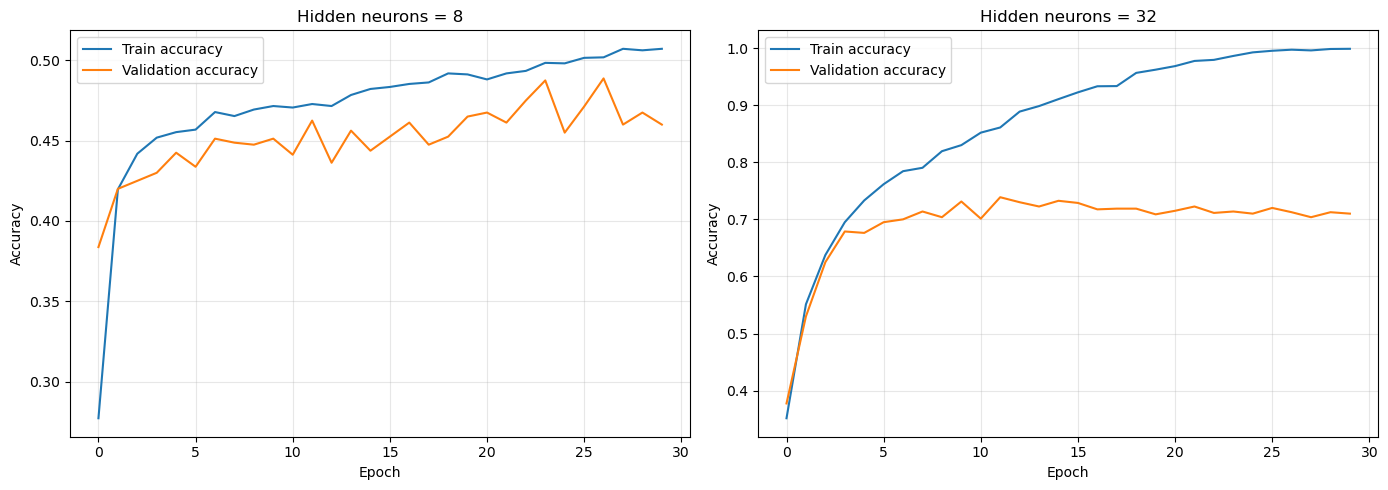

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, hist, title in [
    (axes[0], history_h8, "Hidden neurons = 8"),
    (axes[1], history_h32, "Hidden neurons = 32"),
]:
    ax.plot(hist["train_acc"], label="Train accuracy")
    ax.plot(hist["val_acc"], label="Validation accuracy")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.set_title(title)
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [17]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Model": "Baseline (hidden=16)",
        "Trainable params": n_params,
        "Final train acc": round(history_baseline["train_acc"][-1], 4),
        "Final val acc": round(history_baseline["val_acc"][-1], 4),
    },
    {
        "Model": "Hidden=8",
        "Trainable params": n_params_h8,
        "Final train acc": round(history_h8["train_acc"][-1], 4),
        "Final val acc": round(history_h8["val_acc"][-1], 4),
    },
    {
        "Model": "Hidden=32",
        "Trainable params": n_params_h32,
        "Final train acc": round(history_h32["train_acc"][-1], 4),
        "Final val acc": round(history_h32["val_acc"][-1], 4),
    },
])
comparison


,Model,Trainable params,Final train acc,Final val acc
0,Baseline (hidden=16),116092,0.9728,0.6963
1,Hidden=8,58452,0.5072,0.4600
2,Hidden=32,231372,0.9988,0.7100


### 2(d) Critical analysis

Hidden = 32 has the highest validation accuracy. 

Increasing the number of parameters not necessarily meaningfully improve validation accuracy. In our case, the increase in validation accuracy is marginal, considering the huge increase in parameters and training cost.

The hidden = 8 model seems to be underfitted as the training and validation accuracy is relatively low for 30 epochs when compared to the other models. The baseline model seems to have some overfitting, since the traing accuracy kept rising, but the validation accuracy did not rise in a similar way, it sort of stabilized around epoch 12-13. The hidden = 32 model is more prominently overfitted, as after a few epochs, the validation accuracy is flat, while training accuracy shoots up and reaches 99 percent, highlighting model basically memorizing training features, but not able to further improve generalization, hence no improvement in validation accuracy over 20+ epochs.


## 3. Multi-Label Text Classification Using BERT

Dataset: student_8 tweets  
Model: bert-base-uncased 


In [18]:
import json
from pathlib import Path

import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, BertForSequenceClassification, get_linear_schedule_with_warmup

TWEET_DIR = Path.cwd() / "student_8"
LABELS = [
    "anger", "anticipation", "disgust", "fear", "joy", "love",
    "optimism", "pessimism", "sadness", "surprise", "trust",
]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

def load_tweets(path):
    rows = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            if line.strip():
                rows.append(json.loads(line))
    return rows

train_rows = load_tweets(TWEET_DIR / "train.json")
val_rows = load_tweets(TWEET_DIR / "validation.json")
test_rows = load_tweets(TWEET_DIR / "test.json")

print("Train:", len(train_rows), " Val:", len(val_rows), " Test:", len(test_rows))
print("Example tweet:", train_rows[0]["Tweet"])
print("Example labels:", {k: train_rows[0][k] for k in LABELS})

Device: cuda
Train: 3000  Val: 400  Test: 1500
Example tweet: i animated a little thing i might post it tomorrow since itll be a Good Thursday.. nice...
Example labels: {'anger': False, 'anticipation': True, 'disgust': False, 'fear': False, 'joy': True, 'love': False, 'optimism': True, 'pessimism': False, 'sadness': False, 'surprise': False, 'trust': False}


### 3(a) Fine-tuning BERT


In [19]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
MAX_LEN = 128
BERT_EPOCHS = 5
BERT_BATCH = 32
BERT_LR = 2e-5

In [20]:
class TweetDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, idx):
        row = self.rows[idx]
        enc = tokenizer(
            row["Tweet"],
            truncation=True,
            padding="max_length",
            max_length=MAX_LEN,
            return_tensors="pt",
        )
        label_vals = []
        for name in LABELS:
            label_vals.append(row[name])
        labels = torch.tensor(label_vals, dtype=torch.float)

        return {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "labels": labels,
        }

In [21]:
train_loader = DataLoader(TweetDataset(train_rows), batch_size=BERT_BATCH, shuffle=True)
val_loader = DataLoader(TweetDataset(val_rows), batch_size=BERT_BATCH, shuffle=False)
test_loader = DataLoader(TweetDataset(test_rows), batch_size=BERT_BATCH, shuffle=False)

batch = next(iter(train_loader))
print("Batch input_ids:", batch["input_ids"].shape)
print("Batch labels:", batch["labels"].shape)

Batch input_ids: torch.Size([32, 128])
Batch labels: torch.Size([32, 11])


In [22]:
bert_model = BertForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=len(LABELS),
    problem_type="multi_label_classification", 
)
bert_model = bert_model.to(device)
print("Trainable parameters:", count_trainable(bert_model))


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable parameters: 109490699


In [23]:
optimizer = torch.optim.AdamW(bert_model.parameters(), lr=BERT_LR) #AdamW seems to work better than Adam for BERT.
total_steps = len(train_loader) * BERT_EPOCHS
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=0,
    num_training_steps=total_steps,
)

In [24]:
def run_bert_epoch(model, loader, train=True):
    model.train(train)
    total_loss = 0.0
    n = 0

    for batch in loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        if train:
            optimizer.zero_grad()

        out = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = out.loss

        if train:
            loss.backward()
            optimizer.step()
            scheduler.step()

        total_loss += loss.item() * labels.size(0)
        n += labels.size(0)

    return total_loss / n

In [25]:
bert_history = {"train_loss": [], "val_loss": []}
for epoch in range(1, BERT_EPOCHS + 1):
    train_loss = run_bert_epoch(bert_model, train_loader, train=True)
    val_loss = run_bert_epoch(bert_model, val_loader, train=False)
    bert_history["train_loss"].append(train_loss)
    bert_history["val_loss"].append(val_loss)
    print(f"Epoch {epoch}/{BERT_EPOCHS}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}")

Epoch 1/5  train_loss=0.4925  val_loss=0.3921
Epoch 2/5  train_loss=0.3723  val_loss=0.3495
Epoch 3/5  train_loss=0.3273  val_loss=0.3387
Epoch 4/5  train_loss=0.3023  val_loss=0.3314
Epoch 5/5  train_loss=0.2892  val_loss=0.3297


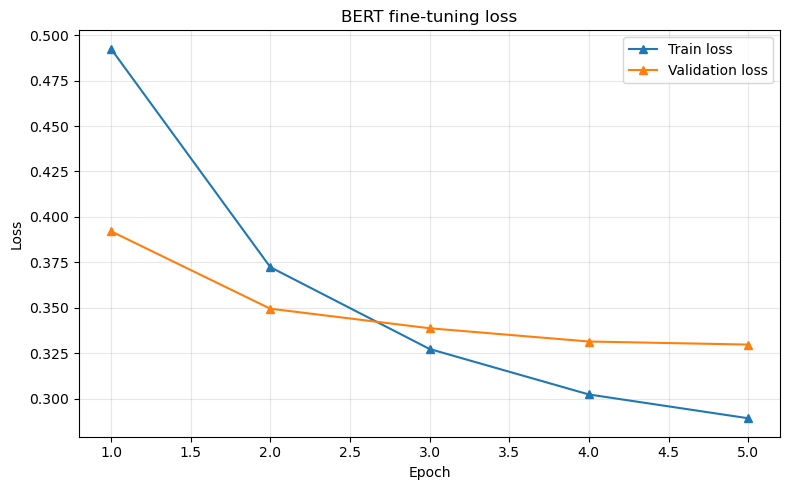

In [26]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, BERT_EPOCHS + 1), bert_history["train_loss"], marker="^", label="Train loss")
plt.plot(range(1, BERT_EPOCHS + 1), bert_history["val_loss"], marker="^", label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("BERT fine-tuning loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
THRESH = 0.5 # for sigmoid 
def predict_all(model, loader):
    model.eval()
    all_true, all_pred = [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)
            logits = model(input_ids=input_ids, attention_mask=attention_mask).logits
            preds = (torch.sigmoid(logits) >= THRESH).float()
            all_true.append(labels)
            all_pred.append(preds)
    return torch.cat(all_true), torch.cat(all_pred)


y_true, y_pred = predict_all(bert_model, test_loader)
print("Test predictions shape:", y_pred.shape)
#print("On device:", y_pred.device)


Test predictions shape: torch.Size([1500, 11])


#### 3(b) Exact-match accuracy

In [28]:
exact_match = (y_pred == y_true).all(dim=1).float().mean().item()
print(f"Exact-match accuracy (test): {exact_match:.4f}")

Exact-match accuracy (test): 0.2653


#### 3(c) At-least-one-label accuracy


In [29]:
shared_positive = (y_pred == 1) & (y_true == 1)
hit = shared_positive.any(dim=1)
at_least_one = hit.float().mean().item()
print(f"At-least-one-label accuracy (test): {at_least_one:.4f}")

At-least-one-label accuracy (test): 0.8100


#### 3(d) Micro-F1 score


In [30]:
tp = ((y_pred == 1) & (y_true == 1)).sum().float()
fp = ((y_pred == 1) & (y_true == 0)).sum().float()
fn = ((y_pred == 0) & (y_true == 1)).sum().float()

precision = (tp / (tp + fp)).item()
recall = (tp / (tp + fn)).item()
micro_f1 = 2 * precision * recall / (precision + recall)

print(f"Micro precision: {precision:.4f}")
print(f"Micro recall:    {recall:.4f}")
print(f"Micro-F1 (test): {micro_f1:.4f}")


Micro precision: 0.7816
Micro recall:    0.5692
Micro-F1 (test): 0.6587


In [31]:
metrics_table = pd.DataFrame([
    {"Metric": "Exact-match accuracy", "Test score": round(exact_match, 4)},
    {"Metric": "At-least-one-label accuracy", "Test score": round(at_least_one, 4)},
    {"Metric": "Micro-F1", "Test score": round(micro_f1, 4)},
])
metrics_table

,Metric,Test score
0,Exact-match accuracy,0.2653
1,At-least-one-label accuracy,0.8100
2,Micro-F1,0.6587


#### 3(e) Comparison and interpretation
Exact match produces the lowest test score as it is the strictest metric. We have 11 labels here and all needs to exactly match for a tweet. At least one label is a more liberal metric, as long as one label hits, its counted as correct. Hence, it has the highest score. Macro F1 sits between them. It considers both precision and recall, and hence a more balanced metric. And I would prefer micro F1 over both as the more informative metric, since it is not seeking a perfect all 11 label match, while also weighting in the effect of false positives and false negatives (false positive hurts precision while false negatives hurt recall, hurting f1 score overall). 